# Correlation Functions for Rubin Light Curves

**version 0.1**

***

AA Miller (Northwestern/CIERA/SKAI)  
16 Nov 2026

In this notebook we will build functions to measure the autocorrelation function (ACF) and the structure function (SF), from scratch in pure python.

We will start with simulated light curves and then apply the ACF and SF to light curves of periodic variable stars from Rubin Data Preview 1 (DP1).

**Learning Objectives**

By the end of this notebook you should be able to:

1. Calculate the ACF of an evenly sampled time series, and use it to distinguish white noise, correlated noise, and periodic signals.
2. Explain why the standard ACF estimator cannot be used for unevenly sampled data, such as LSST light curves.
3. Build the discrete correlation function (DCF) and the structure function (SF) for unevenly sampled data with heteroskedastic uncertainties.
4. Apply the DCF and SF to Rubin DP1 light curves, and connect the results to the Rubin observing cadence.

*Note* – DP1 light curves are proprietary to Rubin data-rights holders until 30 June 2027. This notebook must be run on the Rubin Science Platform (RSP). Do not copy the light curves, or any files derived from them, off of the RSP.

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
%matplotlib inline

## Problem 0) Helper functions

Execute the cell below to create two helper functions that simulate periodic and stochastic variability. 

`simulate_drw` simulates a damped random walk (DRW) with characteristic timescale `tau` and long-term standard deviation `sigma`.

In [3]:
def simulate_sinusoid(t, period, amplitude, sigma_noise, rng):
    '''
    Sinusoid with Gaussian noise evaluated at times t

    Parameters
    ----------
    t : array-like
        observation times

    period : float
        period of the sinusoid (same units as t)

    amplitude : float
        semi-amplitude of the sinusoid

    sigma_noise : float
        standard deviation of the Gaussian (white) noise added to each observation

    rng : numpy.random.Generator
        random number generator, e.g., np.random.default_rng(seed)

    Returns
    -------
    y : array-like
        simulated flux at each time in t
    '''
    return amplitude * np.sin(2 * np.pi * t / period) + rng.normal(0, sigma_noise, len(t))


def simulate_drw(t, tau, sigma, rng):
    '''
    Damped random walk (Ornstein-Uhlenbeck process) evaluated at times t

    Uses the exact update between consecutive observations, so the times
    can be evenly or unevenly spaced. No measurement noise is added.

    Parameters
    ----------
    t : array-like
        observation times, sorted in increasing order

    tau : float
        characteristic (damping) timescale of the DRW (same units as t)

    sigma : float
        long-term standard deviation of the DRW

    rng : numpy.random.Generator
        random number generator, e.g., np.random.default_rng(seed)

    Returns
    -------
    x : array-like
        simulated DRW signal at each time in t
    '''
    x = np.empty(len(t))
    x[0] = rng.normal(0, sigma)
    for i in range(1, len(t)):
        a = np.exp(-(t[i] - t[i-1]) / tau)
        x[i] = a * x[i-1] + rng.normal(0, sigma * np.sqrt(1 - a**2))
    return x

## Problem 1) The ACF for Evenly Sampled Data

Recall from the lecture that for $N$ evenly spaced observations, the ACF at lag $k$ is estimated as:

$$\hat\rho(k) = \frac{\sum_{i=1}^{N-k}(y_i-\bar y)(y_{i+k}-\bar y)}{\sum_{i=1}^{N}(y_i-\bar y)^2}$$

We will now build a function to calculate the ACF.

**Problem 1a**

Simulate three light curves observed every 24 hr for 500 days:

- white noise with $\sigma = 1$ (i.e., a Gaussian)
- a DRW with $\tau = 20~\mathrm{d}$ and $\sigma = 1$, plus white noise with $\sigma = 0.2$
- a sinusoid with $P = 50~\mathrm{d}$ and amplitude 1, plus white noise with $\sigma = 0.5$

Plot the three light curves.

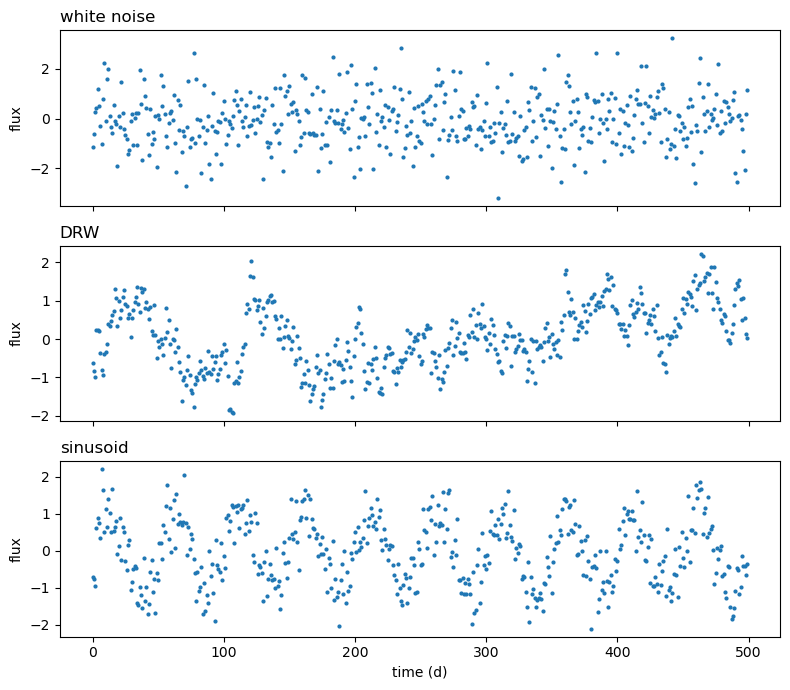

In [12]:
rng = np.random.default_rng(seed=1891)
t = np.arange(500, dtype=float) 

y_white = rng.normal(0, 1, len(t))
y_drw = simulate_drw(t, 20, 1, rng) + rng.normal(0, 0.2, len(t)) # complete
y_sin = simulate_sinusoid(t, 50, 1, 0.5, rng)# complete

fig, ax = plt.subplots(3, 1, figsize=(8, 7), sharex=True)
for axis, y, label in zip(ax, [y_white, y_drw, y_sin], ["white noise", "DRW", "sinusoid"]):
    axis.plot(t, y, "o", ms=2)
    axis.set_ylabel("flux")
    axis.set_title(label, loc="left")
ax[2].set_xlabel("time (d)")
fig.tight_layout()

**Problem 1b**

The estimator requires the mean-subtracted light curve, $y_i - \bar y$.

Write a function `center` that returns the mean-subtracted light curve.

In [13]:
def center(y):
    '''
    Subtract the mean from a light curve

    Parameters
    ----------
    y : array-like
        flux measurements

    Returns
    -------
    yc : array-like
        mean-subtracted flux measurements
    '''
    yc = y - np.mean(y)# complete
    return yc

**Problem 1c**

The numerator and the denominator of the estimator are both sums of products of the centered light curve with a shifted copy of itself (the denominator is the $k = 0$ case).

Write a function `lag_sum` that returns $\sum_{i=1}^{N-k} y_{c,i}\, y_{c,i+k}$ for a centered light curve $y_c$.

*Hint* – can you avoid a `for` loop using a `NumPy` vectorized operation?

In [66]:
def lag_sum(yc, k):
    '''
    Sum of the products of a centered light curve and a copy shifted by k samples

    Parameters
    ----------
    yc : array-like
        mean-subtracted flux measurements

    k : int
        lag, in number of samples

    Returns
    -------
    total : float
        sum over i of yc[i] * yc[i+k]
    '''
    N = len(yc)
    total = np.sum([yc[i] * yc[i+k] for i in range(0, N-k)])

    
    # complete
    return total

**Problem 1d**

Confirm that for $k = 0$, `lag_sum` should equal the sum of the squared centered light curve. (This should be possible with any of the simulated light curves)

In [67]:
yc = center(y_drw) # complete
print(lag_sum(yc, 0), np.sum(yc**2))

324.5206393930848 324.5206393930848


**Problem 1e**

Write a function `acf` that returns the lags $k = 0, 1, \ldots, k_\mathrm{max}-1$ and the ACF at each lag.

In [68]:
def acf(y, kmax):
    '''
    Autocorrelation function of an evenly sampled light curve

    Parameters
    ----------
    y : array-like
        flux measurements (evenly spaced in time)

    kmax : int
        the ACF is calculated for lags 0, 1, ..., kmax-1

    Returns
    -------
    lags : array-like
        lags, in number of samples

    rho : array-like
        ACF at each lag
    '''
    yc = center(y)
    lags = np.arange(0, kmax).astype(int)
   
    rho =  [lag_sum(yc, lags[i]) for i in lags]/np.sum((yc**2))

    return lags, rho

In [69]:
np.arange(0, 5).astype(int)[4]

np.int64(4)

**Problem 1f**

Calculate the ACF of each of the three simulated light curves for $k_\mathrm{max} = 250$. Plot the results.

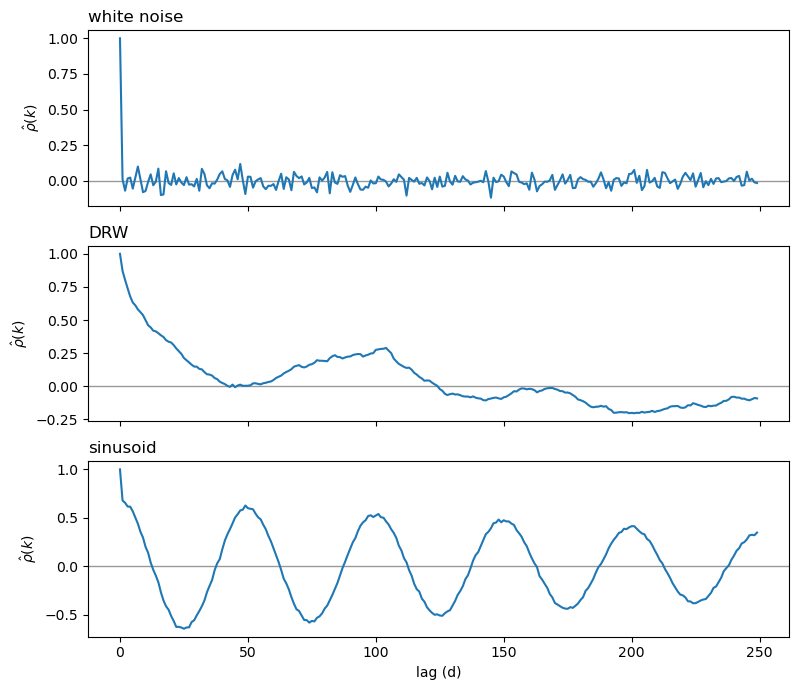

In [70]:
fig, ax = plt.subplots(3, 1, figsize=(8, 7), sharex=True)
for axis, y, label in zip(ax, [y_white, y_drw, y_sin], ["white noise", "DRW", "sinusoid"]):
    lags, rho = acf(y, 250)[0], acf(y, 250)[1]
    axis.axhline(0, color="0.6", lw=1)
    axis.plot(lags, rho)
    axis.set_ylabel(r"$\hat\rho(k)$")
    axis.set_title(label, loc="left")
ax[2].set_xlabel("lag (d)")
fig.tight_layout()

**Problem 1g**

Describe the ACF of each light curve.

For the DRW, at what lag does the ACF fall to $1/e$? How does this compare to $\tau$?

For the sinusoid, why is $\hat\rho(1)$ noticeably less than 1, even though the signal barely changes in 1 d?

*write your answer here*

**Problem 1h**

As noted in the lecture, the first peak of the ACF provides a simple estimate of the period.

Write a function `first_peak` that returns the lag of the first local maximum in the ACF that occurs *after* the ACF has become negative. Only consider local maxima with $\hat\rho > 0$.

Your function should ignore any lags where the ACF is `NaN` (this will be important later).

Use `first_peak` to estimate the period of the simulated sinusoid.

In [ ]:
def first_peak(lags, rho):
    '''
    Lag of the first positive local maximum after the ACF first becomes negative

    Parameters
    ----------
    lags : array-like
        lags

    rho : array-like
        ACF (or DCF) at each lag, can include NaN values

    Returns
    -------
    peak_lag : float
        lag of the first peak (NaN if no peak is found)
    '''
    # complete 
    # complete
    # complete

In [ ]:
lags, rho = acf(y_sin, 250)
print("ACF period estimate = {} d".format(first_peak(lags, rho)))

## Problem 2) Rubin Light Curves Are Not Evenly Sampled

The DP1 light curves were obtained with LSSTComCam during commissioning (late Nov to mid Dec 2024). They are forced PSF photometry on each calibrated visit image (`dp1.ForcedSource`), so the fluxes are direct-image fluxes, not difference-image fluxes.

The stars were selected as periodic variables following Malanchev et al. (2025). There are no labels for the individual stars, but the duration is short so they are mostly $\sim$$1~\mathrm{day}$ period sources (i.e., RR Lyrae, $\delta$ Scuti stars, and contact or ellipsoidal binaries).

**Getting access to the DSFP light-curve data**

1. Go to https://id.lsst.cloud and log in with your RSP account.
2. In the left sidebar, click Groups → All Groups, find g_dsfp, and click Join.
3. Log out of the Notebook Aspect completely and start a new server. A server that was already running won’t see the new group.

**Problem 2a**

Load the catalog of variable stars in a dataframe called `cat`, as well as the "best" periodic variables into a dataframe called `show`.

How many stars are there in each field in `cat`?

In [ ]:
D = "/home/amiller/dsfp_dp1_variables/release_v1"
sys.path.insert(0, D)
import dp1_lc_reader as R

cat = R.load_catalog()
show = R.load_showcase()

cat.groupby(["field"]).size()

**Problem 2b**

Select the star from `show` with the largest number of good epochs (`n_good`), and load its light curve with `R.load_lightcurve`.

Plot `psfFlux` (with uncertainties) vs. `mjd` for the $g$, $r$, $i$, and $z$ bands, using a different color for each band.

In [ ]:
star = # complete
lc = R.load_lightcurve(star["objectId"])

fig, ax = plt.subplots(figsize=(10, 4))
for band in ["g", "r", "i", "z"]:
    in_band = lc["band"] == band
    ax.errorbar(lc["mjd"][in_band], lc["psfFlux"][in_band], lc["psfFluxErr"][in_band],
                fmt="o", ms=3, label=band)
ax.set_xlabel("MJD")
ax.set_ylabel("psfFlux (nJy)")
ax.legend()

**Problem 2c**

Calculate the time between consecutive observations (in any band) and plot a histogram of these separations in minutes. Use logarithmic bins.

In [ ]:
dt_consecutive = # complete

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist( # complete
ax.set_xscale("log")
ax.set_xlabel("time between consecutive observations (min)")
ax.set_ylabel("N")

**Problem 2d**

Describe the sampling of this light curve. What are the typical separations between observations within a night? Between nights?

*write your answer here*


**Problem 2e**

Simulate a sinusoid with $P = 0.1~\mathrm{d}$, amplitude 1, and white noise with $\sigma = 0.3$ at the observation times of this star (simulate observations in a single filter for each observation of the example star, regardless of the filter of the real obsrvation).

Calculate the ACF of this simulated light curve with your `acf` function from Problem 1 for $k_\mathrm{max} = 60$, and plot it vs. $k$.

In [ ]:
t_rubin = # complete
y_rubin = # complete

lags, rho = # complete

fig, ax = plt.subplots(figsize=(7, 4))
ax.axhline(0, color="0.6", lw=1)
ax.plot(lags, rho, "o-")
ax.set_xlabel("lag (samples)")
ax.set_ylabel(r"$\hat\rho(k)$")
fig.tight_layout()

**Problem 2f**

The simulated signal is perfectly periodic. Why does the ACF from Problem 2e not show a clean periodic pattern?

*write your answer here*


## Problem 3) The Discrete Correlation Function

The DCF (Edelson & Krolik 1988) uses every pair of observations, and bins the pairs by their separation in time:

$$\mathrm{UDCF}_{ij} = \frac{(y_i - \bar y)(y_j - \bar y)}{s^2 - \bar\sigma^2}$$

$$\mathrm{DCF}(\tau) = \frac{1}{M}\sum \mathrm{UDCF}_{ij}, \quad \mathrm{for~the~} M \mathrm{~pairs~with~} |\Delta t_{ij} - \tau| < \Delta\tau/2$$

where $s^2$ is the sample variance and $\bar\sigma^2$ is the mean of the squared measurement uncertainties.

As in **Problem 1** we will build a function to calculate the DCF.

**Problem 3a**

Write a function `all_pairs` that returns the indices $i$ and $j$ of every pair of observations with $i < j$, along with the time separation $\Delta t_{ij} = |t_j - t_i|$.

Hint: `np.triu_indices(N, k=1)` returns the indices of every pair with $i < j$.

Confirm that the number of pairs is $N(N-1)/2$.

In [ ]:
def all_pairs(t):
    '''
    Indices and time separations for every pair of observations

    Parameters
    ----------
    t : array-like
        observation times

    Returns
    -------
    i, j : array-like
        indices of the two observations in each pair (i < j)

    dt : array-like
        time separation for each pair, |t[j] - t[i]|
    '''
    i, j = # complete
    dt = # complete
    return i, j, dt

In [ ]:
i, j, dt = all_pairs(t_rubin)
N = len(t_rubin)
print(len(dt), N * (N - 1) // 2)

**Problem 3b**

Write a function `udcf` that returns the unbinned DCF, $\mathrm{UDCF}_{ij}$, for every pair.

Use `np.var(y, ddof=1)` for the sample variance, $s^2$.

In [ ]:
def udcf(y, yerr, i, j):
    '''
    Unbinned discrete correlation function for each pair of observations

    Parameters
    ----------
    y : array-like
        flux measurements

    yerr : array-like
        flux uncertainties

    i, j : array-like
        indices of the two observations in each pair

    Returns
    -------
    u : array-like
        UDCF for each pair
    '''
    yc = # complete
    s2 = # complete
    sigma2 = # complete
    return # complete

**Problem 3c**

Write a function `bin_pairs` that bins the pairs by their time separation. For each bin, return the bin center, the mean of the values in the bin, the uncertainty on the mean (the standard deviation divided by $\sqrt{M}$), and the number of pairs $M$.

If a bin contains fewer than `min_pairs` pairs, set the mean and uncertainty to `NaN`.

*Note* – `bin_pairs` can be used now for the DCF and in the next problem for the SF.

In [ ]:
def bin_pairs(dt, values, bin_edges, min_pairs=1):
    '''
    Average pair values in bins of time separation

    Parameters
    ----------
    dt : array-like
        time separation for each pair

    values : array-like
        value (e.g., UDCF) for each pair

    bin_edges : array-like
        edges of the time-separation bins

    min_pairs : int (default=1)
        minimum number of pairs required to report a mean

    Returns
    -------
    centers : array-like
        bin centers

    means : array-like
        mean value in each bin (NaN if fewer than min_pairs)

    errs : array-like
        uncertainty on the mean in each bin

    npairs : array-like
        number of pairs in each bin
    '''
    nbins = len(bin_edges) - 1
    centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])
    means = np.full(nbins, np.nan)
    errs = np.full(nbins, np.nan)
    npairs = np.zeros(nbins, dtype=int)

    # complete
    # complete
    # complete
    # complete

    return centers, means, errs, npairs

**Problem 3d**

Use `all_pairs`, `udcf`, and `bin_pairs` to write a function `dcf` that calculates the DCF of a light curve.

In [ ]:
def dcf(t, y, yerr, bin_edges, min_pairs=1):
    '''
    Discrete correlation function of an (unevenly sampled) light curve

    Parameters
    ----------
    t, y, yerr : array-like
        observation times, fluxes, and flux uncertainties

    bin_edges : array-like
        edges of the lag bins

    min_pairs : int (default=1)
        minimum number of pairs required in a bin

    Returns
    -------
    centers, dcf_vals, dcf_errs, npairs : array-like
        lag bin centers, DCF, DCF uncertainty, and number of pairs per bin
    '''
    i, j, dt = # complete
    u = # complete
    return bin_pairs( # complete

**Problem 3e**

Test your DCF on the evenly sampled sinusoid from Problem 1. Use bins of width 1 d centered on the integer lags $1, 2, \ldots, 249$, and uncertainties equal to the noise level ($\sigma = 0.5$).

Plot the DCF and the ACF from **Problem 1f** on the same axes.

Why is the amplitude of the DCF larger than the amplitude of the ACF?

In [ ]:
yerr_sin = 0.5 * np.ones(len(t))
bin_edges = np.arange(0.5, 250, 1)

centers, dcf_vals, dcf_errs, npairs = dcf(t, y_sin, yerr_sin, bin_edges)
lags, rho = acf(y_sin, 250)

fig, ax = plt.subplots(figsize=(8, 4))
ax.axhline(0, color="0.6", lw=1)
ax.plot(lags, rho, label="ACF")
ax.plot(centers, dcf_vals, label="DCF")
ax.set_xlabel("lag (d)")
ax.legend()

*write your answer here*



**Problem 3f**

Now calculate the DCF of the simulated sinusoid at the Rubin observation times from **Problem 2e** (use `yerr = 0.3`). Use bins of width $\Delta\tau = 0.005~\mathrm{d}$ from 0 to 0.5 d, and set `min_pairs = 10` so that bins with very few pairs are excluded.

Make a two-panel figure: the DCF (with uncertainties) in the top panel, and the number of pairs per bin in the bottom panel. Overplot the expected correlation for a sinusoid, $\cos(2\pi\tau/P)$.

In [ ]:
yerr_rubin = # complete
bin_edges = np.arange(0, 0.5 + 0.005, 0.005)
centers, dcf_vals, dcf_errs, npairs = dcf( # complete

fig, ax = plt.subplots(2, 1, figsize=(8, 6), sharex=True)
ax[0].axhline(0, color="0.6", lw=1)
ax[0].errorbar(centers, dcf_vals, dcf_errs, fmt="o", ms=3)
ax[0].plot(centers, np.cos(2 * np.pi * centers / 0.1), label=r"$\cos(2\pi\tau/P)$")
ax[0].legend()
ax[1].step(centers, npairs, where="mid")
ax[0].set_ylabel("DCF")
ax[1].set_ylabel("N pairs")
ax[1].set_xlabel("lag (d)")

**Problem 3g**

Extend the lag range to 0–5 d (keep $\Delta\tau = 0.005~\mathrm{d}$) and replot the number of pairs per bin.

For which lags are there no pairs at all? Why?

In [ ]:
bin_edges_long = np.arange(0, 5 + 0.005, 0.005)
centers_long, dcf_long, dcf_long_errs, npairs_long = dcf( # complete

fig, ax = plt.subplots(figsize=(10, 3))
ax.step(centers_long, npairs_long, where="mid")
ax.set_xlabel("lag (d)")
ax.set_ylabel("N pairs")
fig.tight_layout()

*write your answer here*



**Problem 3h**

Recalculate the DCF from Problem 3f with $\Delta\tau = 0.001$, $0.005$, and $0.05~\mathrm{d}$. Plot the three results. Use `first_peak` to estimate the period from each.

How does the bin width affect the DCF?

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4))
for width in [0.001, 0.005, 0.05]:
    edges = np.arange(0, 0.5 + width, width)
    c, d, e, n = dcf(t_rubin, y_rubin, yerr_rubin, edges)
    ax.plot(c, d, "o-", ms=3, label=r"$\Delta\tau$ = {} d".format(width))
    print("bin width = {} d, period estimate = {:.4f} d".format(width, first_peak(c, d)))
ax.set_xlabel("lag (d)")
ax.set_ylabel("DCF")
ax.legend()

*write your answer here*


## Problem 4) The Structure Function

The SF measures the typical squared difference between observations separated by $\tau$:

$$SF^2(\tau) = \langle [y(t+\tau) - y(t)]^2 \rangle$$

For a stationary process,

$$SF^2(\tau) = 2\sigma^2[1 - \rho(\tau)] + 2\sigma_n^2.$$

**Problem 4a**

Write two functions: `sf_pairs`, which returns $(y_j - y_i)^2$ for every pair, and `noise_pairs`, which returns the noise contribution to each pair, $\sigma_i^2 + \sigma_j^2$.

In [ ]:
def sf_pairs(y, i, j):
    '''Squared flux difference for each pair of observations'''
    return # complete


def noise_pairs(yerr, i, j):
    '''Expected noise contribution to the squared difference for each pair'''
    return # complete

**Problem 4b**

Use `all_pairs`, `sf_pairs`, `noise_pairs`, and `bin_pairs` to write a function `structure_function`.

It should return the bin centers, $SF^2$, the uncertainty on $SF^2$, the number of pairs, and the mean noise contribution in each bin.

In [ ]:
def structure_function(t, y, yerr, bin_edges, min_pairs=1):
    '''
    Structure function (squared) of an (unevenly sampled) light curve

    Parameters
    ----------
    t, y, yerr : array-like
        observation times, fluxes, and flux uncertainties

    bin_edges : array-like
        edges of the lag bins

    min_pairs : int (default=1)
        minimum number of pairs required in a bin

    Returns
    -------
    centers, sf2, sf2_errs, npairs, noise2 : array-like
        lag bin centers, SF^2, SF^2 uncertainty, number of pairs, and
        mean noise contribution (sigma_i^2 + sigma_j^2) in each bin
    '''
    i, j, dt = # complete
    centers, sf2, sf2_errs, npairs = # complete
    centers, noise2, noise2_errs, npairs = # complete
    return centers, sf2, sf2_errs, npairs, noise2

**Problem 4c**

Simulate a DRW with $\tau = 100~\mathrm{d}$ and $\sigma = 0.2$, observed 400 times at random (sorted) times over 2000 d, with white noise $\sigma_n = 0.05$.

Calculate the SF using 30 logarithmically spaced bins between 0.1 d and 2000 d. Plot $SF^2$ vs. $\tau$ on log-log axes, with the expectation, $2\sigma^2[1 - e^{-\tau/100}] + 2\sigma_n^2$, and the measured noise contribution in each bin overplotted.

In [ ]:
t_drw = # complete
y_drw_irr = simulate_drw(# complete
yerr_drw = 0.05 * np.ones(len(t_drw))

bin_edges = np.logspace(-1, np.log10(2000), 31)
centers, sf2, sf2_errs, npairs, noise2 = structure_function( # complete

tt = np.logspace(-1, np.log10(2000), 200)
fig, ax = plt.subplots(figsize=(7, 5))
ax.errorbar(centers, sf2, sf2_errs, fmt="o", label="data")
ax.plot(tt, 2 * 0.2**2 * (1 - np.exp(-tt / 100)) + 2 * 0.05**2, label="expectation")
ax.plot(centers, noise2, "--", label="noise")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel(r"$\tau$ (d)")
ax.set_ylabel(r"$SF^2$")
ax.legend()

**Problem 4d**

Pretend that you do not know the input parameters. Using only your SF plot, estimate $\sigma$, $\sigma_n$, and $\tau$ for the DRW.

What limits the precision of your estimate of $\sigma$?

*write your answer here*



**Problem 4e**

Calculate the SF of the simulated sinusoid at the Rubin observation times (**Problem 2e**), using linear bins of width 0.005 d from 0 to 0.5 d and `min_pairs = 10`.

For a sinusoid with amplitude $A$, the expected SF is $SF^2(\tau) = A^2[1 - \cos(2\pi\tau/P)] + 2\sigma_n^2$. Overplot this expectation.

At which lags does the SF reach its minimum?

In [ ]:
bin_edges = np.arange(0, 0.5 + 0.005, 0.005)
centers, sf2, sf2_errs, npairs, noise2 = structure_function(t_rubin, y_rubin, yerr_rubin, bin_edges, min_pairs=10)

fig, ax = plt.subplots(figsize=(8, 4))
ax.errorbar(centers, sf2, sf2_errs, fmt="o", ms=3, label="data")
ax.plot(centers, 1 - np.cos(2 * np.pi * centers / 0.1) + 2 * 0.3**2, label="expectation")
ax.set_xlabel(r"$\tau$ (d)")
ax.set_ylabel(r"$SF^2$")
ax.legend()

*write your answer here*



## Challenge Problem) Rubin DP1 Periodic Variables

Apply your newly created tools to the DP1 light curves.

The bands have different mean fluxes and different amplitudes, so we cannot simply combine all of the observations. Instead, light curves much be standardized in each band (subtract the mean and divide by the standard deviation) before combining them.

**Challenge Problem a**

Write a function `clean_lightcurve` that keeps only the observations:
- in the bands `g`, `r`, `i`, or `z` (following Kostya's paper)
- with finite `psfFlux` and `psfFluxErr`
- with `psfFluxErr > 0`

In [ ]:
def clean_lightcurve(lc, bands=("g", "r", "i", "z")):
    '''
    Remove observations in unwanted bands or with bad photometry

    Parameters
    ----------
    lc : pandas DataFrame
        light curve from R.load_lightcurve

    bands : tuple (default=("g", "r", "i", "z"))
        bands to keep

    Returns
    -------
    lc_clean : pandas DataFrame
        cleaned light curve
    '''
    # complete

**Challenge Problem b**

Write a function `standardize_by_band` that returns numpy arrays `t`, `y`, and `yerr`, where in each band the flux has been converted to $(f - \bar f_\mathrm{band}) / s_\mathrm{band}$ and the uncertainties have been divided by $s_\mathrm{band}$.

In [ ]:
def standardize_by_band(lc):
    '''
    Standardize the flux in each band and combine all bands

    Parameters
    ----------
    lc : pandas DataFrame
        cleaned light curve

    Returns
    -------
    t, y, yerr : array-like
        times, standardized fluxes, and standardized uncertainties
    '''
    # complete

**Challenge Problem c**

Select the showcase star with the shortest catalog period (`period_final_d`). Load, clean, and standardize its light curve.

Make a two-panel figure showing the standardized light curve vs. time (left), and phase-folded at `period_final_d` using `R.phase_fold` (right). Color the points by band.

In [ ]:
# complete

**Challenge Problem d**

Calculate the SF for the same star and bins. Plot $SF^2$ with vertical lines at integer multiples of $P_\mathrm{cat}$, and a horizontal line at the mean noise level.

Where are the minima of the SF? How close do they get to the noise level?

In [ ]:
# complete

The minima of the SF fall at integer multiples of $P_\mathrm{cat}$. How close the minima get to the noise level depends on the star. Phase lags and amplitude differences between bands, small period errors, and any non-periodic variability (or systematics) all keep the SF minima above the noise floor.